# KỸ THUẬT 2: Ngưỡng thích nghi bằng ảnh tích phân (Integral Image)

## 1. Thông tin chung
* **Căn cứ:** Tài liệu *Computer_Vision 40.pdf* (mục 3.1–3.6, trang 6–8).
* **Nội dung yêu cầu:** Cài đặt 4 hàm bắt buộc và tiến hành 3 thí nghiệm (A, B, C).
* **Cách thực thi:** Mở VS Code $\rightarrow$ chọn kernel Python $\rightarrow$ **Run All**. Dữ liệu đầu ra (ảnh, file CSV) được lưu tại thư mục `ket_qua/`.
* **Công cụ sử dụng:** Python, NumPy, Matplotlib và ChatGPT (hỗ trợ phát triển/kiểm thử).

## 2. Cơ sở toán học
**Ảnh tích phân (với hàng/cột đệm 0):**
$$S[y+1,x+1] = \sum_{i=0}^{y}\sum_{j=0}^{x} I[i,j]$$

**Tổng vùng chữ nhật (truy vấn với độ phức tạp $O(1)$):**
$$\Sigma = S[y_2+1,x_2+1] - S[y_1,x_2+1] - S[y_2+1,x_1] + S[y_1,x_1]$$

**Các phương pháp tính ngưỡng thích nghi:**
* **Bradley–Roth:** $T(x,y) = m(x,y)(1-t)$ (Mặc định $t=0.15$).
* **Sauvola:** $T(x,y) = m(x,y) \left[ 1 + k \left( \frac{s(x,y)}{128} - 1 \right) \right]$ (Mặc định $k=0.34$).
* **Nhị phân hóa:** Nếu $I(x,y) < T(x,y)$, pixel được gán **0** (mực/chữ đen); ngược lại gán **255** (nền trắng).

## 3. Cài đặt (mục 3.5)

Bốn hàm yêu cầu đúng chữ ký: `integral_image`, `box_sum`, `local_mean_std`, `adaptive_threshold`. Các hàm tính cửa sổ không có vòng lặp Python qua từng pixel; bảng bình phương dùng `int64`, phương sai dùng `np.maximum(var,0)`.

In [1]:
import csv
import time
from pathlib import Path
import numpy as np
import matplotlib
matplotlib.use('Agg')  # chay tren VS Code/terminal khong can cua so giao dien
import matplotlib.pyplot as plt
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure

RESULTS = Path.cwd() / 'ket_qua'
RESULTS.mkdir(exist_ok=True)

## 4. Cấu trúc hàm & Xử lý kỹ thuật
* **`integral_image`:** Khởi tạo ảnh tích phân. Bắt buộc dùng kiểu dữ liệu `int64` để tránh hiện tượng tràn số (overflow) khi tính tổng mảng lớn.
* **`box_sum`:** Tính tổng pixel trong một cửa sổ cục bộ dựa trên ảnh tích phân.
* **`local_mean_std`:** Trích xuất giá trị trung bình $m(x,y)$ và độ lệch chuẩn $s(x,y)$. Sử dụng `np.maximum(var, 0)` để triệt tiêu phương sai âm phát sinh do sai số dấu phẩy động.
* **`adaptive_threshold`:** Thực thi tính toán ngưỡng cục bộ. Cần xử lý chặt chẽ các vùng biên ảnh và trường hợp ngoại lệ như `radius=0`.

In [2]:
def integral_image(img):
    """Tạo bảng tổng tích lũy S, có thêm hàng 0 và cột 0."""
    img = np.asarray(img)
    if img.ndim != 2:
        raise ValueError("Đầu vào phải là ảnh xám 2 chiều")

    h, w = img.shape
    # Phải chuyển sang int64 TRƯỚC khi cộng dồn để tránh tràn số.
    img64 = img.astype(np.int64)
    S = np.zeros((h + 1, w + 1), dtype=np.int64)
    S[1:, 1:] = np.cumsum(np.cumsum(img64, axis=0), axis=1)
    return S


def box_sum(S, y1, x1, y2, x2):
    """Tổng vùng từ (y1,x1) đến (y2,x2), tính cả các ô biên."""
    # Có hàng/cột 0 nên không cần xử lý riêng khi x1 hoặc y1 bằng 0.
    # Chỉ dùng bốn giá trị trên bảng S, không lặp qua từng pixel.
    y1, x1 = np.asarray(y1), np.asarray(x1)
    y2, x2 = np.asarray(y2), np.asarray(x2)
    return (S[y2 + 1, x2 + 1] - S[y1, x2 + 1]
            - S[y2 + 1, x1] + S[y1, x1])


def local_mean_std(img, radius):
    """Tính trung bình và độ lệch chuẩn ở mỗi pixel bằng hai bảng tích phân."""
    img = np.asarray(img)
    if img.ndim != 2 or img.dtype != np.uint8:
        raise ValueError("Cần ảnh xám uint8 (H, W)")
    if not isinstance(radius, (int, np.integer)) or radius < 0:
        raise ValueError("radius phải là số nguyên không âm")

    h, w = img.shape
    y, x = np.ogrid[:h, :w]  # y là hàng; x là cột
    y1 = np.maximum(y - radius, 0)
    y2 = np.minimum(y + radius, h - 1)
    x1 = np.maximum(x - radius, 0)
    x2 = np.minimum(x + radius, w - 1)

    # Ở mép ảnh, cửa sổ bị cắt nên diện tích thực tế có thể nhỏ hơn.
    area = (y2 - y1 + 1) * (x2 - x1 + 1)

    img64 = img.astype(np.int64)
    S1 = integral_image(img64)
    S2 = integral_image(img64 * img64)  # Không bình phương trực tiếp uint8!
    mean = box_sum(S1, y1, x1, y2, x2) / area
    mean_square = box_sum(S2, y1, x1, y2, x2) / area

    variance = np.maximum(mean_square - mean ** 2, 0.0)
    std = np.sqrt(variance)
    return mean.astype(np.float64), std.astype(np.float64)


def adaptive_threshold(img, radius=15, method='bradley', t=0.15, k=0.34):
    """Nhị phân hóa: chữ tối = 0 (đen), nền = 255 (trắng)."""
    img = np.asarray(img)
    if img.ndim != 2 or img.dtype != np.uint8:
        raise ValueError("Cần ảnh xám uint8 (H, W)")

    mean, std = local_mean_std(img, radius)
    if method in ('bradley', 'bradley-roth'):
        threshold = mean * (1 - t)
    elif method == 'sauvola':
        threshold = mean * (1 + k * (std / 128 - 1))
    else:
        raise ValueError("method chỉ được là 'bradley' hoặc 'sauvola'")

    return np.where(img < threshold, 0, 255).astype(np.uint8)




## 5. Kiểm thử số học
Kiểm tra tổng vùng 3×3, xử lý góc ảnh, vùng đơn sắc, `radius=0`, kiểu dữ liệu, đầu ra nhị phân và nguy cơ tràn số.

In [3]:
def run_tests():
    a = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]], dtype=np.uint8)
    s = integral_image(a)
    assert s.shape == (4, 4) and s.dtype == np.int64
    assert np.all(s[0, :] == 0) and np.all(s[:, 0] == 0)
    assert box_sum(s, 0, 0, 2, 2) == 45
    assert box_sum(s, 1, 1, 2, 2) == 28
    assert np.array_equal(box_sum(s, np.array([0, 1]), 0, 2, 2), [45, 39])
    m, d = local_mean_std(a, radius=1)
    assert np.isclose(m[1, 1], 5)
    assert np.isclose(d[1, 1], np.std(a.astype(float)))
    assert np.isclose(m[0, 0], 3)  # (1+2+4+5)/4
    assert np.isclose(d[0, 0], np.std([1, 2, 4, 5]))
    m0, s0 = local_mean_std(a, radius=0)
    assert np.allclose(m0, a) and np.allclose(s0, 0)
    for meth in ('bradley', 'sauvola'):
        out = adaptive_threshold(a, method=meth)
        assert out.shape == a.shape and out.dtype == np.uint8
        assert set(np.unique(out)).issubset({0, 255})
    big = np.full((200, 300), 255, dtype=np.uint8)
    sbig = integral_image(big.astype(np.int64)**2)
    assert sbig[-1, -1] == 255**2 * 200 * 300  # > 2^31: khong tran int32
    uniform = np.full((40, 40), 120, dtype=np.uint8)
    um, us = local_mean_std(uniform, radius=7)
    assert np.all(um == 120) and np.all(us == 0)
    print('PASS: 4 ham, bien anh, vector hoa, binh phuong int64, variance>=0')

In [4]:
run_tests()

PASS: 4 ham, bien anh, vector hoa, binh phuong int64, variance>=0


## 6. Dựng bộ ảnh thử

- **Ảnh không đều sáng:** nền tối bên trái, sáng bên phải, có thêm biến thiên theo hàng.
- **Ảnh nền phẳng rộng:** vùng trống có nhiễu Gaussian đủ mạnh để dễ phát sinh chấm đen giả.

Ảnh được tổng hợp có chủ ý nhằm bộc lộ điểm mạnh/yếu của thuật toán, chứ không phải ảnh chụp đo thực tế. `ink` là mask chữ gốc để có thể đếm sai số.

In [5]:
def text_mask(h=240, w=460, flat=False):
    fig = Figure(figsize=(w / 100, h / 100), dpi=100, facecolor='white')
    canvas = FigureCanvasAgg(fig)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, w)
    ax.set_ylim(h, 0)
    ax.axis('off')
    if flat:
        ax.text(17, 56, 'BAI TAP CV', fontsize=26, fontweight='black', color='black')
        ax.text(17, 100, 'NEN PHANG', fontsize=18, fontweight='bold', color='black')
        ax.text(17, 147, 'SAUVOLA', fontsize=24, fontweight='black', color='black')
        # Nua ben phai va phan duoi co vung phang KHONG co chu
    else:
        ax.text(20, 62, 'COMPUTER VISION', fontsize=24, fontweight='black', color='black')
        ax.text(20, 118, 'BRADLEY ROTH', fontsize=22, fontweight='bold', color='black')
        ax.text(20, 170, 'Sauvola & Integral Image', fontsize=18, fontweight='bold', color='black')
        ax.text(20, 215, '2026', fontsize=19, fontweight='bold', color='black')
    canvas.draw()
    rgba = np.asarray(canvas.buffer_rgba())
    mask = np.zeros((h, w), dtype=bool)
    ch, cw = rgba.shape[:2]
    mask[:min(h,ch), :min(w,cw)] = rgba[:min(h,ch), :min(w,cw), 0] < 190
    return mask


def make_scene(h=240, w=460, flat=False, seed=42):
    yy, xx = np.mgrid[:h, :w]
    ink = text_mask(h, w, flat=flat)
    rng = np.random.default_rng(seed)
    if flat:
        # Vung nen phang + nhieu gauss du de Bradley nhan nham thanh cham den.
        background = 125.0 + 1.5 * np.sin(xx / 70.0)
        sigma_noise = 18.0
        darkness = 88.0
    else:
        # Chieu sang KHONG deu trai->phai + bong chay doc.
        background = 80.0 + 158.0 * xx / max(w-1, 1) + 14.0 * np.sin(yy / 45.0)
        sigma_noise = 2.0
        darkness = 88.0
    img = np.clip(background - darkness * ink + rng.normal(0, sigma_noise, (h, w)),
                  0, 255).astype(np.uint8)
    return img, ink


def save_image(img, filename, title=None):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.imshow(img, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    if title:
        ax.set_title(title)
    ax.axis('off')
    fig.tight_layout()
    fig.savefig(RESULTS / filename, dpi=150)
    plt.close(fig)


def grid_plot(imgs, titles, filename, cols, width=19, row_h=2.75):
    rows = int(np.ceil(len(imgs) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(width, row_h*rows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        if i < len(imgs):
            ax.imshow(imgs[i], cmap='gray', vmin=0, vmax=255, interpolation='nearest')
            ax.set_title(titles[i], fontsize=10)
        ax.axis('off')
    fig.tight_layout(pad=1.0)
    fig.savefig(RESULTS / filename, dpi=155)
    plt.close(fig)


def segmentation_scores(binary, ink, region=None):
    pred = binary == 0
    valid = np.ones(ink.shape, bool) if region is None else region
    tp = np.count_nonzero(pred & ink & valid)
    fp = np.count_nonzero(pred & ~ink & valid)
    fn = np.count_nonzero(~pred & ink & valid)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
    return (precision, recall, f1, fp)

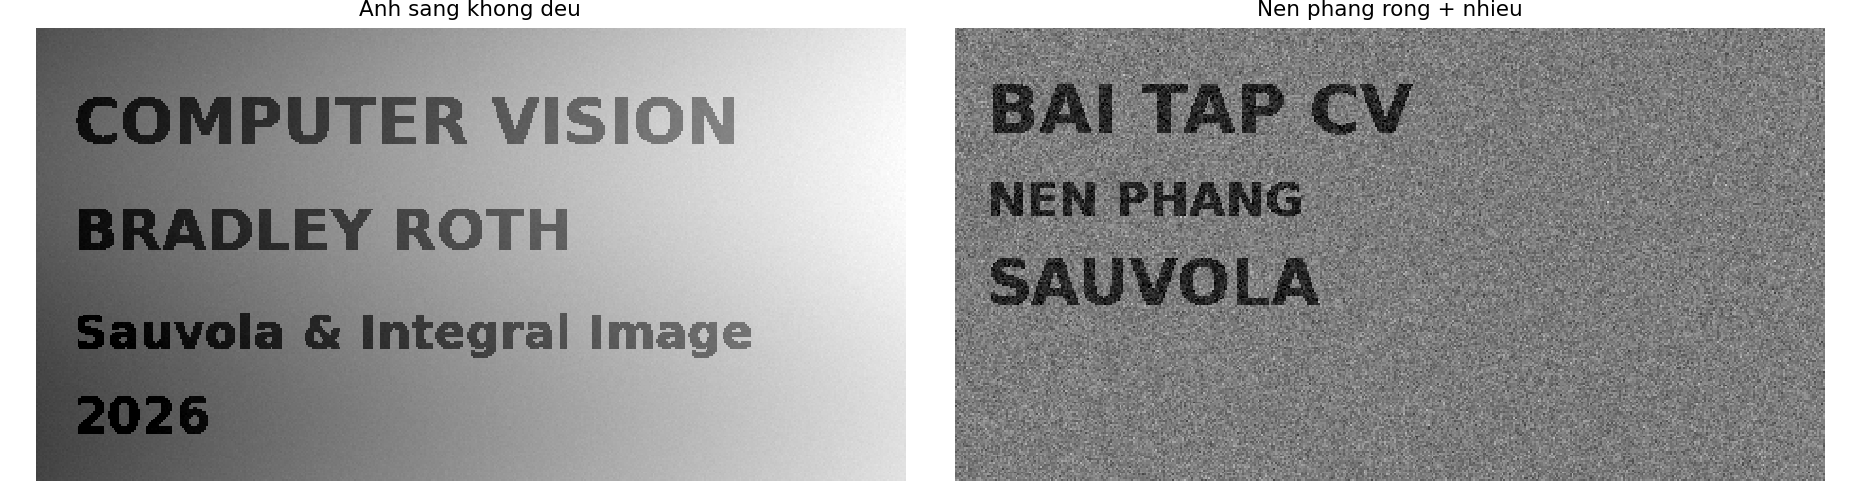

In [6]:
uneven, uneven_gt = make_scene()
flat, flat_gt = make_scene(flat=True)
grid_plot([uneven,flat], ['Anh sang khong deu','Nen phang rong + nhieu'], 'anh_nguon_so_sanh.png', cols=2, width=12, row_h=3.25)
from IPython.display import display, Image
display(Image(filename=str(RESULTS/'anh_nguon_so_sanh.png'), width=1050))

## Các thử nghiệm đánh giá (Độ phức tạp $O(HW)$)
* **Kiểm chứng cơ sở:** Xác thực độ chính xác của 4 hàm thông qua ma trận ảnh nhỏ, đối chiếu với kết quả tính tay.
* **Thí nghiệm A (Khảo sát tham số):** Đánh giá tác động của bán kính cửa sổ (`radius`) và tham số ngưỡng ($t, k$). Theo dõi các giới hạn như hiện tượng "rỗng nét chữ" khi chọn cửa sổ quá lớn.
* **Thí nghiệm B (So sánh thuật toán):** Đối chiếu chất lượng phân ngưỡng giữa các phương pháp: Cố định, Otsu, Bradley–Roth, và Sauvola trên các điều kiện ảnh phức tạp (độ sáng không đồng đều, nền nhiễu).
* **Thí nghiệm C (Đo lường hiệu năng):** Đo và đối chiếu thời gian chạy của 3 cách tính trung bình cục bộ khác nhau để chứng minh ưu thế về tốc độ của ảnh tích phân.

## 7. Thí nghiệm A — ảnh hưởng của tham số (mục 3.6a)

Quét **7 giá trị radius = {1,3,7,15,31,127,511}**, **3 giá trị t = {0.05,0.15,0.25}** cho Bradley–Roth và **3 giá trị k = {0.20,0.34,0.50}** cho Sauvola.

**Dự kiến:** radius rất nhỏ làm rỗng nét chữ, radius vừa đủ giúp giữ nguyên nét; radius cực lớn dùng cùng thống kê toàn ảnh, mất tính thích nghi. `radius` hợp lý phụ thuộc **độ dày nét chữ**, **kích thước chữ** và **quy mô biến thiên ánh sáng**.

In [7]:
def experiment_a(img):
    radii = [1, 3, 7, 15, 31, 127, 511]
    t_values = [0.05, 0.15, 0.25]
    k_values = [0.20, 0.34, 0.50]
    b_imgs = [adaptive_threshold(img, radius=r, t=t) for t in t_values for r in radii]
    b_titles = [f'r={r}, t={t:.2f}' for t in t_values for r in radii]
    grid_plot(b_imgs, b_titles, 'A_Bradley_quet_radius_t.png', cols=len(radii), width=21, row_h=3.0)
    s_imgs = [adaptive_threshold(img, radius=r, method='sauvola', k=k)
              for k in k_values for r in radii]
    s_titles = [f'r={r}, k={k:.2f}' for k in k_values for r in radii]
    grid_plot(s_imgs, s_titles, 'A_Sauvola_quet_radius_k.png', cols=len(radii), width=21, row_h=3.0)

    # Chu co net day: voi r=1, pixel ben trong net khong du khac biet voi lan can.
    compare = [img] + [adaptive_threshold(img, radius=r, t=0.15) for r in [1, 3, 15, 511]]
    grid_plot(compare, ['Anh goc', 'r=1: rong ruot', 'r=3', 'r=15: phu hop',
                       'r=511: nguong toan cuc'], 'A_hieu_ung_ban_kinh.png', cols=5, width=19)

    # r >= max(H, W) thi moi pixel deu su dung cung cua so la toan bo anh.
    global_mean = float(img.mean())
    global_binary = np.where(img < global_mean*(1-0.15), 0, 255).astype(np.uint8)
    assert np.array_equal(adaptive_threshold(img, radius=511, t=0.15), global_binary)
    print('A: 7 radius x 3 t; 7 radius x 3 k; r=511 trung dung nguong mean toan cuc.')
    return radii, t_values, k_values

A: 7 radius x 3 t; 7 radius x 3 k; r=511 trung dung nguong mean toan cuc.
A_hieu_ung_ban_kinh.png


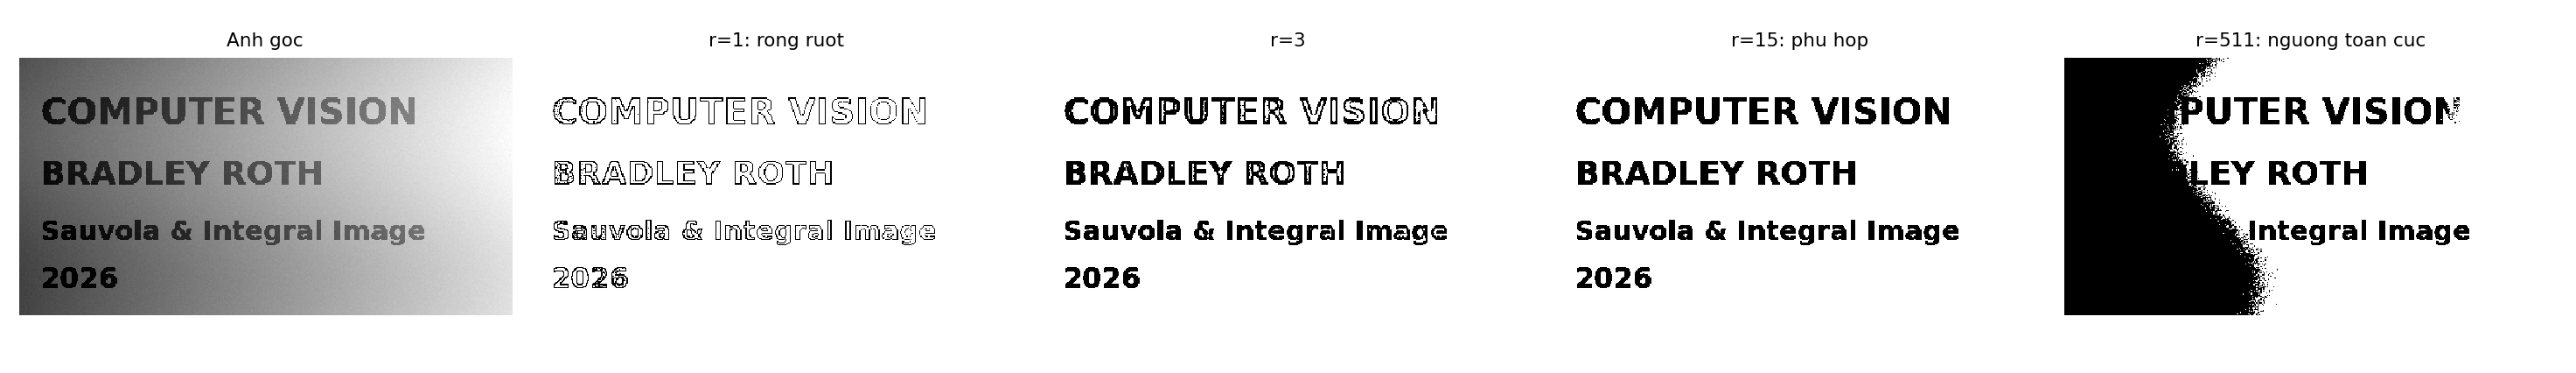

A_Bradley_quet_radius_t.png


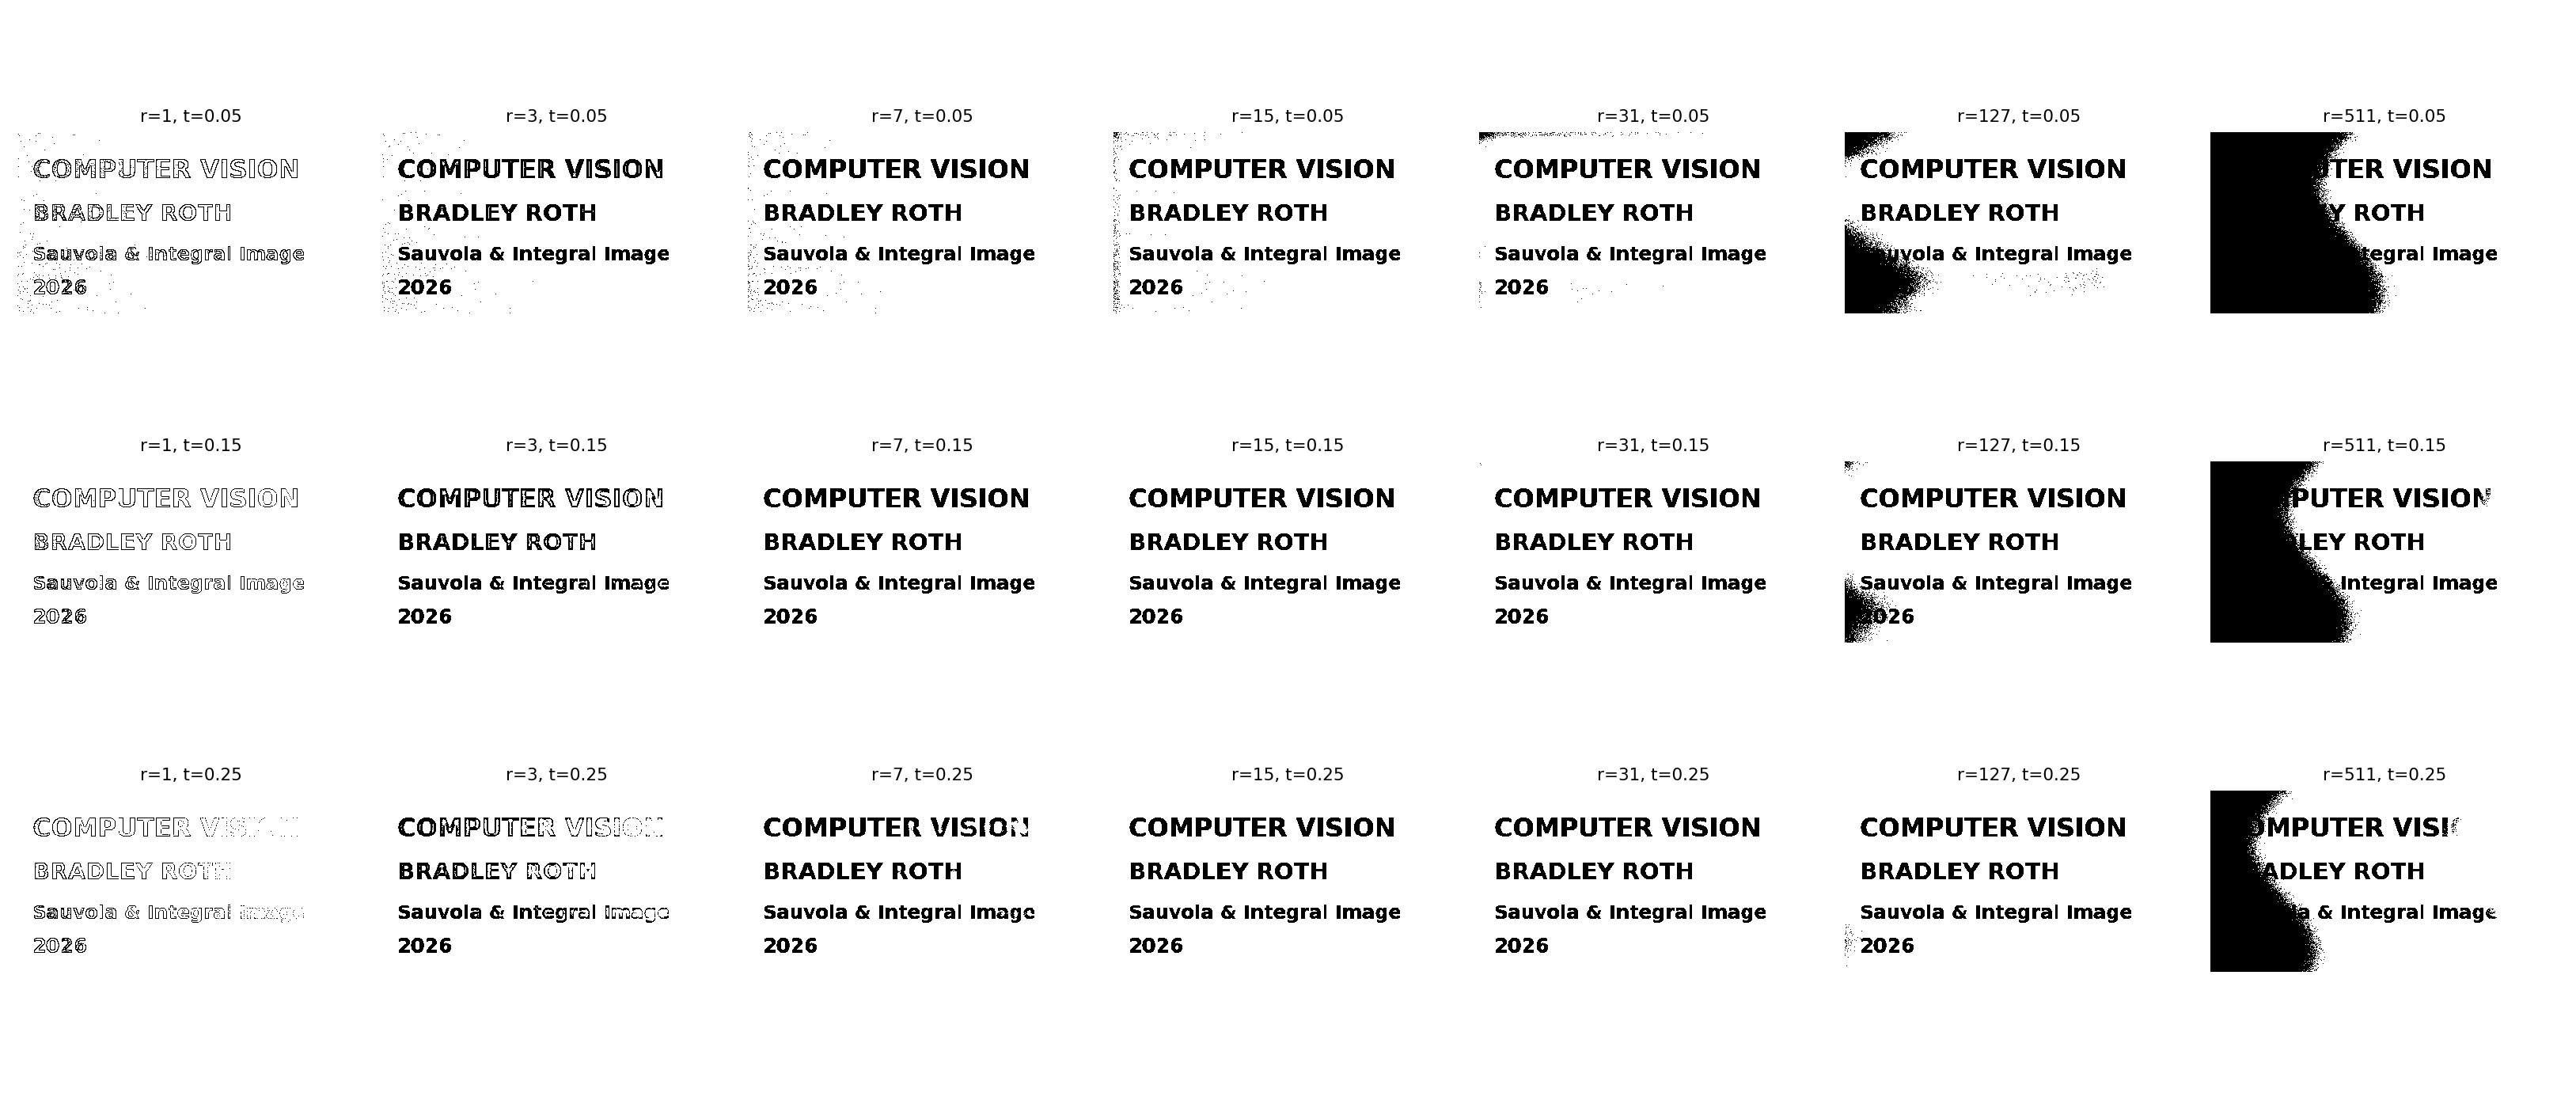

A_Sauvola_quet_radius_k.png


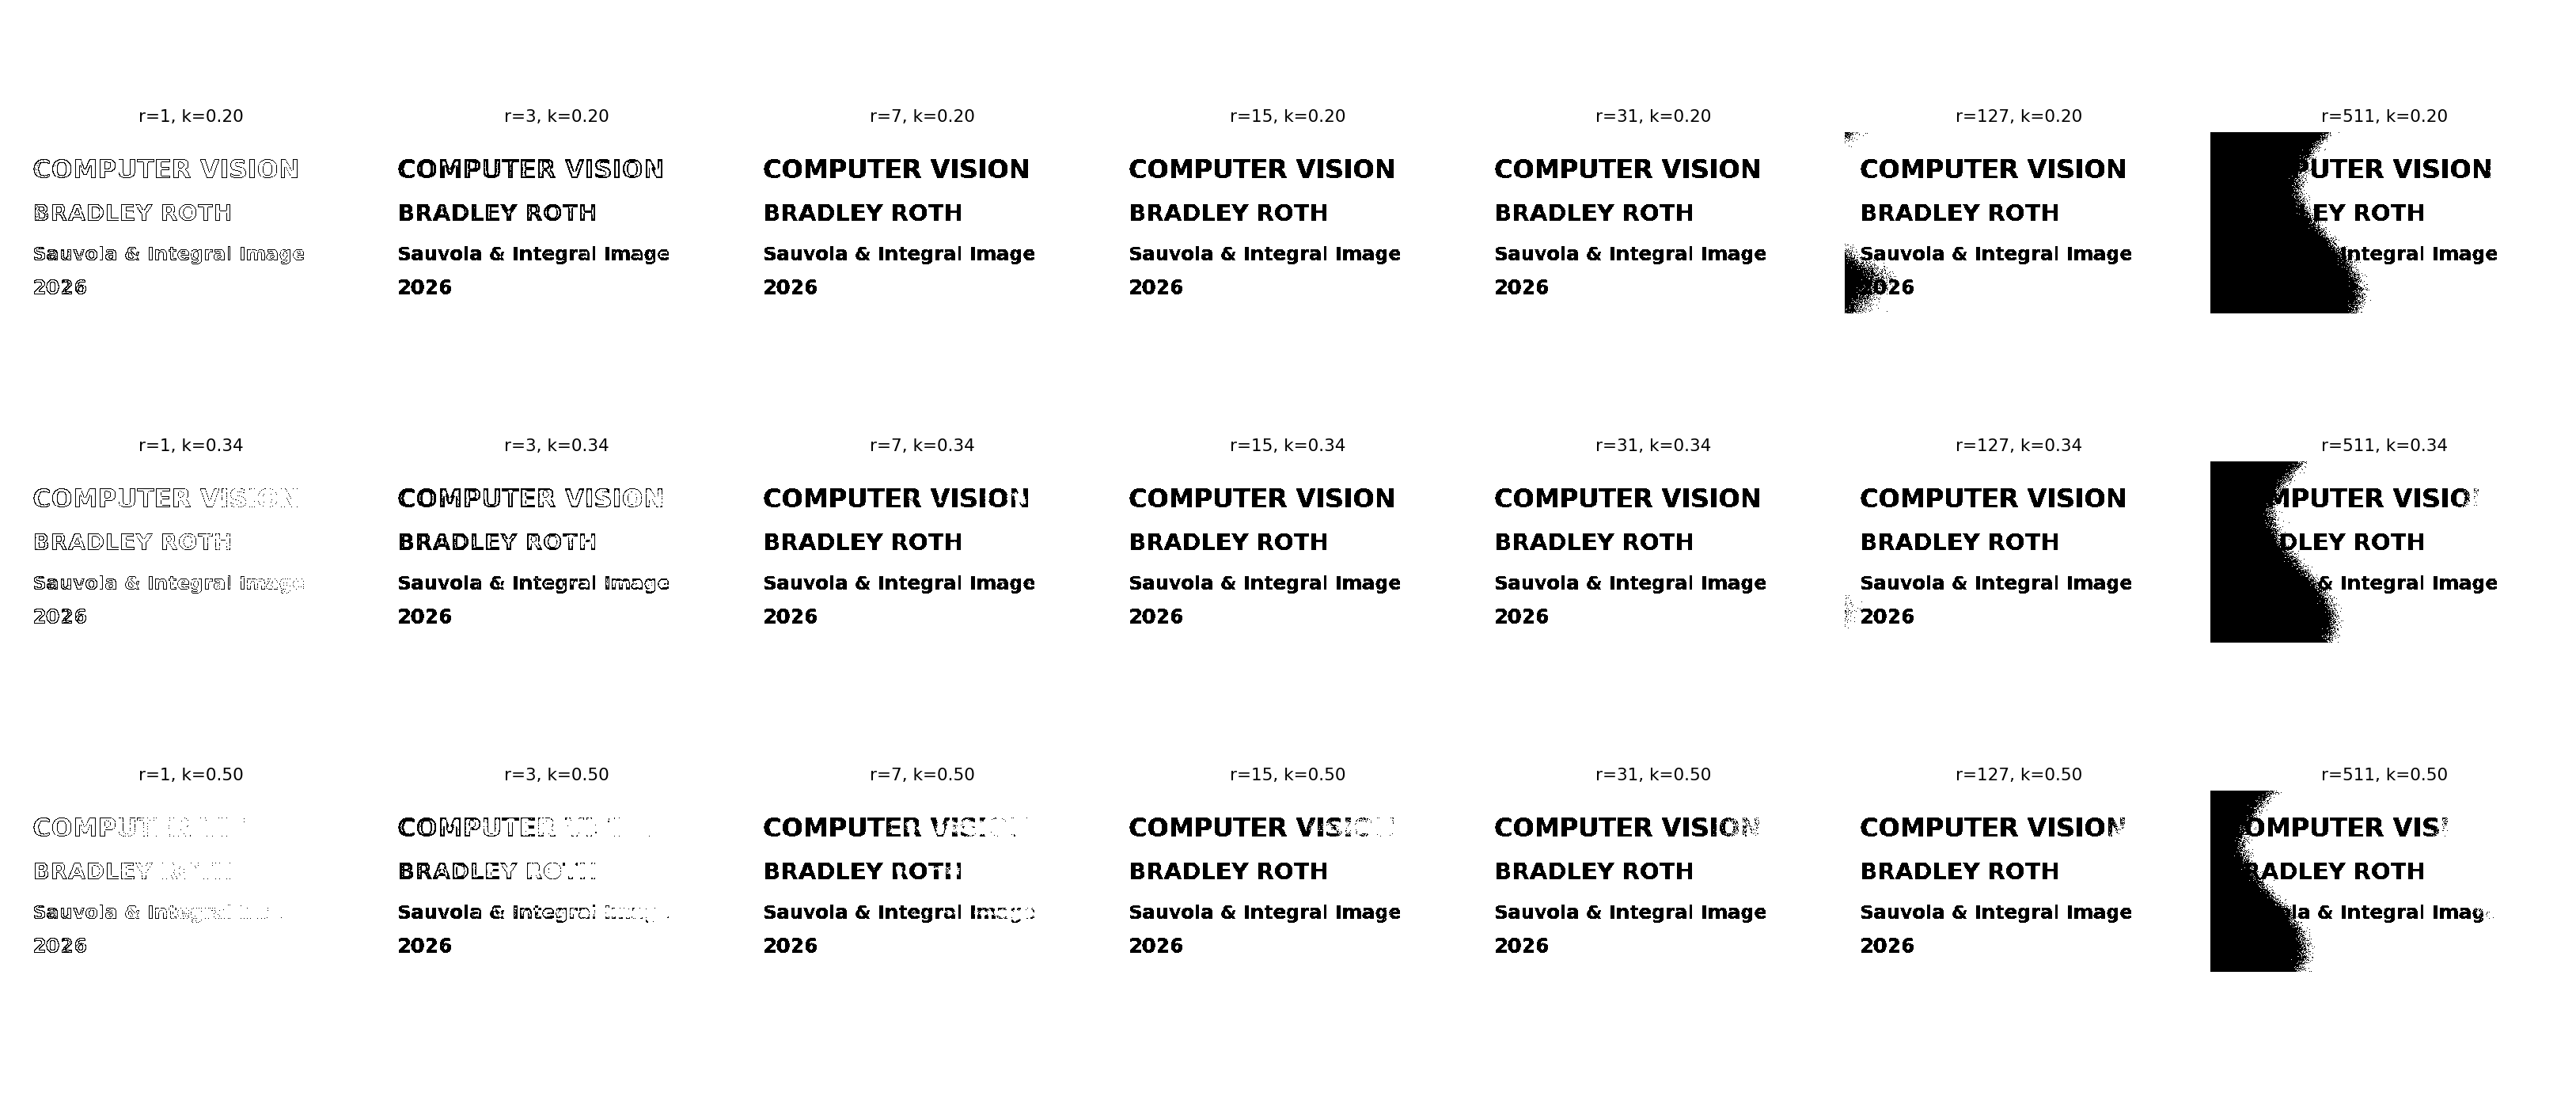

In [8]:
radii, t_values, k_values = experiment_a(uneven)
for pic in ['A_hieu_ung_ban_kinh.png','A_Bradley_quet_radius_t.png','A_Sauvola_quet_radius_k.png']:
    print(pic)
    display(Image(filename=str(RESULTS/pic), width=1250))

**Nhận xét A:** Ảnh r=1 có thể chỉ còn đường viền xung quanh nét chữ (lõi chữ bị mất). Với ảnh tạo ra ở đây, r≈7–31 thường dễ đọc hơn; r=511 **trùng chính xác** với quy tắc ngưỡng theo trung bình toàn cục của Bradley–Roth. Với `t` tăng, ngưỡng giảm nên chỉ những điểm thực sự tối mới thành chữ (chữ có thể bị mỏng/mất). Giá trị cụ thể cần chọn theo kích cỡ chữ và mức tương phản của ảnh.

## 8. Thí nghiệm B — đối chiếu 4 phương pháp (mục 3.6b)

Trên **cùng một ảnh**, đặt cạnh nhau: ngưỡng cố định T=128; Otsu toàn cục; Bradley–Roth; Sauvola. Lặp lại cho ảnh **ánh sáng không đều** và ảnh **nền phẳng rộng có nhiễu**.

Otsu ở đây được viết từ histogram và phương sai liên lớp để không gọi hàm cấm. Bổ sung bảng Precision, Recall, F1 và false-positive pixel (thông tin vượt yêu cầu tối thiểu).

In [9]:
def otsu_manual(img):
    """Otsu tu np.bincount va between-class variance; KHONG dung ham cam."""
    hist = np.bincount(img.ravel(), minlength=256).astype(np.float64)
    prob = hist / hist.sum()
    w0 = np.cumsum(prob)
    mu0 = np.cumsum(prob * np.arange(256))
    total_mean = mu0[-1]
    score = np.zeros(256, dtype=np.float64)
    valid = (w0 > 0) & (w0 < 1)
    score[valid] = ((total_mean*w0[valid] - mu0[valid])**2 /
                    (w0[valid] * (1-w0[valid])))
    return int(np.argmax(score[:-1]))


def experiment_b(uneven, uneven_gt, flat, flat_gt):
    rows = []
    for label, img, truth in [('anh_sang_khong_deu', uneven, uneven_gt),
                              ('nen_phang_rong', flat, flat_gt)]:
        otsu_t = otsu_manual(img)
        outputs = [('Anh goc', img),
                   ('Nguong co dinh 128', np.where(img < 128, 0, 255).astype(np.uint8)),
                   (f'Otsu toan cuc (T={otsu_t})', np.where(img <= otsu_t, 0, 255).astype(np.uint8)),
                   ('Bradley-Roth r=15 t=.15', adaptive_threshold(img, 15, 'bradley')),
                   ('Sauvola r=15 k=.34', adaptive_threshold(img, 15, 'sauvola'))]
        grid_plot([x[1] for x in outputs], [x[0] for x in outputs],
                  'B_so_sanh_'+label+'.png', cols=5, width=20, row_h=3.25)
        for method, result in outputs[1:]:
            p, r, f1, fp = segmentation_scores(result, truth)
            rows.append((label, method, round(p, 5), round(r, 5), round(f1, 5), fp))

        if label == 'nen_phang_rong':
            # Vung nen phang khong co chu de do cham den gia (false positives).
            right = np.zeros(img.shape, bool)
            right[:, img.shape[1]*2//3:] = True
            print('B: ti le pixel nen phang bi nhan nham la chu:')
            for method, result in outputs[1:]:
                fp = np.count_nonzero((result == 0) & right & ~truth)
                count = np.count_nonzero(right & ~truth)
                rate = 100*fp/count
                print(f'   {method:32s}: {rate:6.2f}%')
    with open(RESULTS/'B_chi_so_so_sanh.csv', 'w', encoding='utf-8', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(['anh', 'phuong_phap', 'precision', 'recall', 'f1', 'false_positive_pixels'])
        writer.writerows(rows)
    return rows

B: ti le pixel nen phang bi nhan nham la chu:
   Nguong co dinh 128              :  58.62%
   Otsu toan cuc (T=85)            :   1.72%
   Bradley-Roth r=15 t=.15         :  15.12%
   Sauvola r=15 k=.34              :   2.25%
B_so_sanh_anh_sang_khong_deu.png


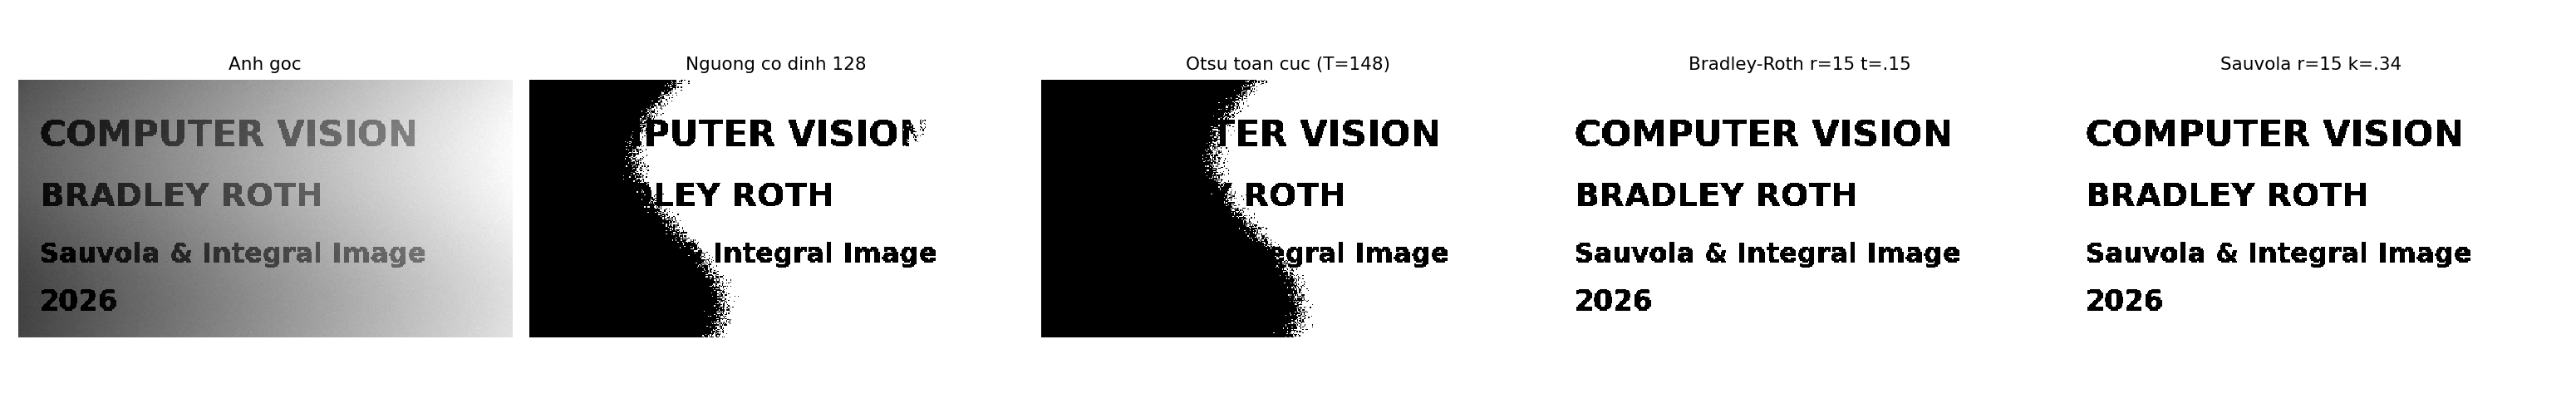

B_so_sanh_nen_phang_rong.png


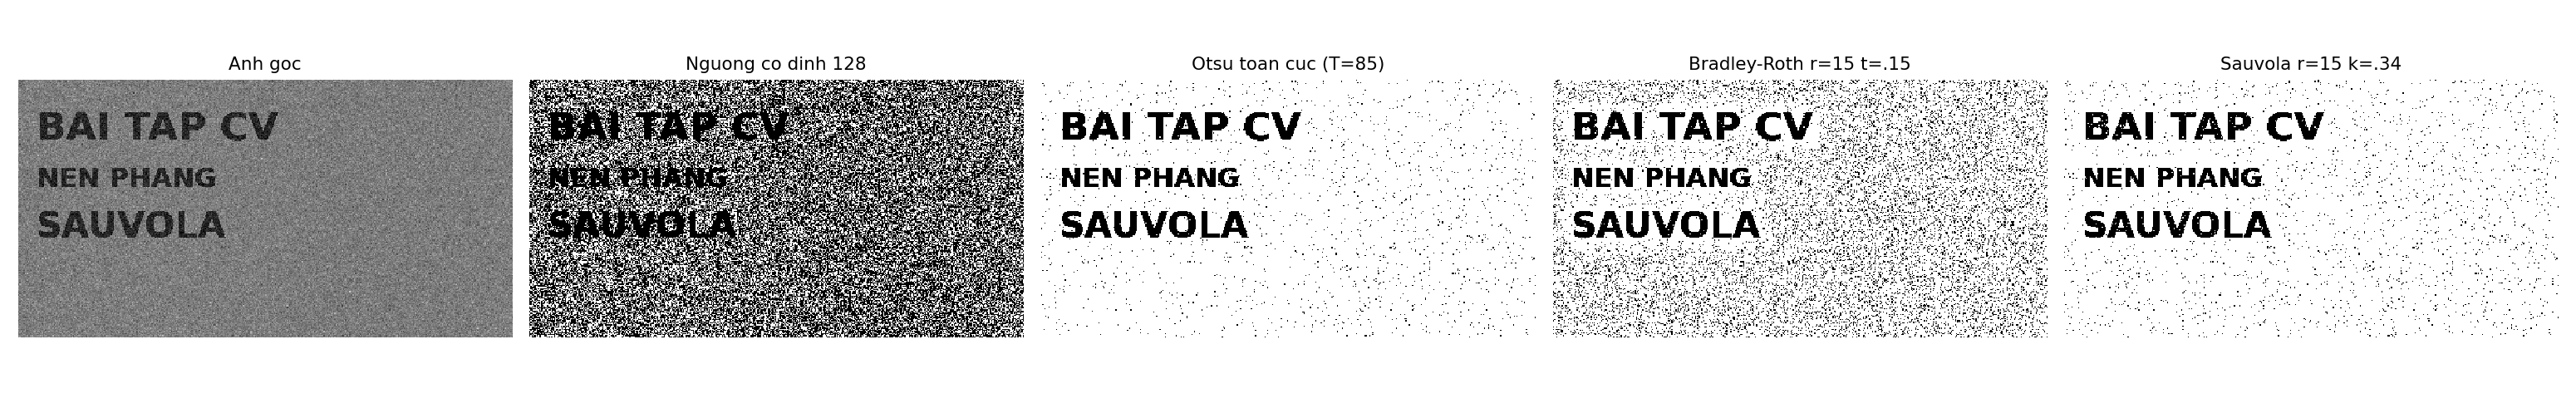

Chi so (anh, phuong phap, precision, recall, F1, false positive):
('anh_sang_khong_deu', 'Nguong co dinh 128', np.float64(0.2785), np.float64(0.98404), np.float64(0.43414), np.int64(28598))
('anh_sang_khong_deu', 'Otsu toan cuc (T=148)', np.float64(0.21321), np.float64(1.0), np.float64(0.35147), np.int64(41398))
('anh_sang_khong_deu', 'Bradley-Roth r=15 t=.15', np.float64(1.0), np.float64(1.0), np.float64(1.0), np.int64(0))
('anh_sang_khong_deu', 'Sauvola r=15 k=.34', np.float64(1.0), np.float64(1.0), np.float64(1.0), np.int64(0))
('nen_phang_rong', 'Nguong co dinh 128', np.float64(0.09922), np.float64(1.0), np.float64(0.18052), np.int64(59395))
('nen_phang_rong', 'Otsu toan cuc (T=85)', np.float64(0.80303), np.float64(0.99648), np.float64(0.88936), np.int64(1599))
('nen_phang_rong', 'Bradley-Roth r=15 t=.15', np.float64(0.33035), np.float64(0.99175), np.float64(0.49561), np.int64(13152))
('nen_phang_rong', 'Sauvola r=15 k=.34', np.float64(0.7595), np.float64(0.97799), np.float64(0.855

In [10]:
scores = experiment_b(uneven,uneven_gt,flat,flat_gt)
for pic in ['B_so_sanh_anh_sang_khong_deu.png','B_so_sanh_nen_phang_rong.png']:
    print(pic)
    display(Image(filename=str(RESULTS/pic), width=1250))
print('Chi so (anh, phuong phap, precision, recall, F1, false positive):')
for row in scores:
    print(row)

**Nhận xét B:** Ngưỡng cố định dễ mất chữ trong ảnh không đều sáng. Bradley–Roth dùng trung bình cửa sổ, còn Sauvola điều chỉnh thêm độ lệch chuẩn. Trên vùng nền phẳng có nhiễu của **bộ ảnh thử này**, Sauvola giảm chấm đen giả đáng kể so với Bradley–Roth; không khẳng định Sauvola luôn thắng trên mọi ảnh. Phần in console cho biết tỷ lệ nhầm thực tế.

**Đọc kết quả đúng:** Trên ảnh nền phẳng của thí nghiệm này, Otsu có F1 cao hơn Sauvola (xem CSV). Vì vậy Sauvola không phải luôn tốt nhất; ưu điểm được minh họa ở đây là giảm false positive so với Bradley–Roth.


## 9. Thí nghiệm C — độ phức tạp theo bán kính (mục 3.4 và 3.6c)

Trên cùng ảnh 160×160 (cửa sổ lớn nhất 129×129 không vượt kích thước ảnh), cùng cách cắt cửa sổ tại biên, so sánh ba cách tính local mean:

1. Tích chập trực tiếp, \(O(r^2)\) thao tác trên mỗi pixel.
2. Tích chập tách được, \(O(r)\) thao tác trên mỗi pixel.
3. Ảnh tích phân, \(O(1)\) thao tác trên mỗi pixel sau bước xây dựng bảng tích phân.

Quét **r∈{1,2,4,8,16,32,64}**, đo bằng `perf_counter` 5 lần và lấy trung vị; **trục Y log**. Ba kết quả trung bình cục bộ đều được kiểm tra `np.allclose`.

In [11]:
def local_mean_direct(img, radius):
    """Tich chap hop truc tiep: O(r^2) / pixel, vong lap tren kernel (khong loop pixel)."""
    h, w = img.shape
    pad = np.pad(img.astype(np.float64), radius, mode='constant')
    sums = np.zeros((h, w), dtype=np.float64)
    for dy in range(2*radius+1):
        for dx in range(2*radius+1):
            sums += pad[dy:dy+h, dx:dx+w]
    yy, xx = np.ogrid[:h, :w]
    area = ((np.minimum(yy+radius,h-1) - np.maximum(yy-radius,0) + 1)
            * (np.minimum(xx+radius,w-1) - np.maximum(xx-radius,0) + 1))
    return sums/area


def local_mean_separable(img, radius):
    """Tich chap hop 2 lan 1D: O(r) / pixel, khong dung boxFilter/blur."""
    h, w = img.shape
    padded = np.pad(img.astype(np.float64), ((0,0),(radius,radius)))
    horiz = np.zeros((h,w), dtype=np.float64)
    for dx in range(2*radius+1):
        horiz += padded[:,dx:dx+w]
    padded = np.pad(horiz, ((radius,radius),(0,0)))
    sums = np.zeros((h,w), dtype=np.float64)
    for dy in range(2*radius+1):
        sums += padded[dy:dy+h,:]
    yy,xx=np.ogrid[:h,:w]
    area = ((np.minimum(yy+radius,h-1)-np.maximum(yy-radius,0)+1)
            * (np.minimum(xx+radius,w-1)-np.maximum(xx-radius,0)+1))
    return sums/area


def local_mean_integral(img, radius):
    """Dung chi 1 summed-area table cho mean: O(HW) tinh S, O(1) / pixel."""
    h, w = img.shape
    s = integral_image(img)
    yy, xx = np.ogrid[:h, :w]
    y1, y2 = np.maximum(yy-radius,0), np.minimum(yy+radius,h-1)
    x1, x2 = np.maximum(xx-radius,0), np.minimum(xx+radius,w-1)
    area = (y2-y1+1)*(x2-x1+1)
    return box_sum(s,y1,x1,y2,x2)/area


def experiment_c():
    # 160x160: cua so lon nhat 129x129 van nam trong kich thuoc anh.
    test_img, _ = make_scene(h=160,w=160, seed=88)
    radii = [1,2,4,8,16,32,64]
    funcs = [local_mean_direct, local_mean_separable, local_mean_integral]
    labels = ['Truc tiep O(r^2)', 'Tach duoc O(r)', 'Anh tich phan O(1)']
    samples = 5
    results = np.zeros((3,len(radii)),dtype=np.float64)
    for j, r in enumerate(radii):
        reference = local_mean_integral(test_img,r)
        for i, fn in enumerate(funcs):
            durations = []
            for _ in range(samples):
                start = time.perf_counter()
                got = fn(test_img,r)
                durations.append((time.perf_counter()-start)*1000)
                assert np.allclose(reference,got,rtol=1e-12,atol=1e-10), (labels[i],r)
            results[i,j] = np.median(durations)

    fig, ax = plt.subplots(figsize=(10,5.5))
    for values, label in zip(results,labels):
        ax.plot(radii,values,marker='o',linewidth=2,label=label)
    ax.set_yscale('log')
    ax.set_xticks(radii)
    ax.set_xlabel('Ban kinh cua so r (pixel)')
    ax.set_ylabel('Thoi gian (ms) - thang log')
    ax.set_title('Thi nghiem C: truc tiep vs tach duoc vs anh tich phan')
    ax.grid(True, which='both', alpha=.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(RESULTS/'C_3_duong_thoi_gian_log.png',dpi=180)
    plt.close(fig)
    with open(RESULTS/'C_bang_thoi_gian.csv','w',newline='',encoding='utf-8') as file:
        writer=csv.writer(file)
        writer.writerow(['radius','direct_ms','separable_ms','integral_ms'])
        for j,r in enumerate(radii):
            writer.writerow([r,*[round(float(results[i,j]),6) for i in range(3)]])
    print('C: 7 radius, 3 phuong phap, moi diem median 5 lan; ket qua 3 cach giong nhau.')
    for j,r in enumerate(radii):
        print(f'   r={r:>2} | direct={results[0,j]:9.3f}ms'
              f' | separable={results[1,j]:8.3f}ms | integral={results[2,j]:8.3f}ms')
    return radii,results

C: 7 radius, 3 phuong phap, moi diem median 5 lan; ket qua 3 cach giong nhau.
   r= 1 | direct=    0.223ms | separable=   0.178ms | integral=   0.462ms
   r= 2 | direct=    0.336ms | separable=   0.200ms | integral=   0.504ms
   r= 4 | direct=    0.872ms | separable=   0.267ms | integral=   0.461ms
   r= 8 | direct=    3.017ms | separable=   0.380ms | integral=   0.487ms
   r=16 | direct=   10.795ms | separable=   0.608ms | integral=   0.462ms
   r=32 | direct=   43.249ms | separable=   1.167ms | integral=   0.462ms
   r=64 | direct=  164.228ms | separable=   2.062ms | integral=   0.465ms


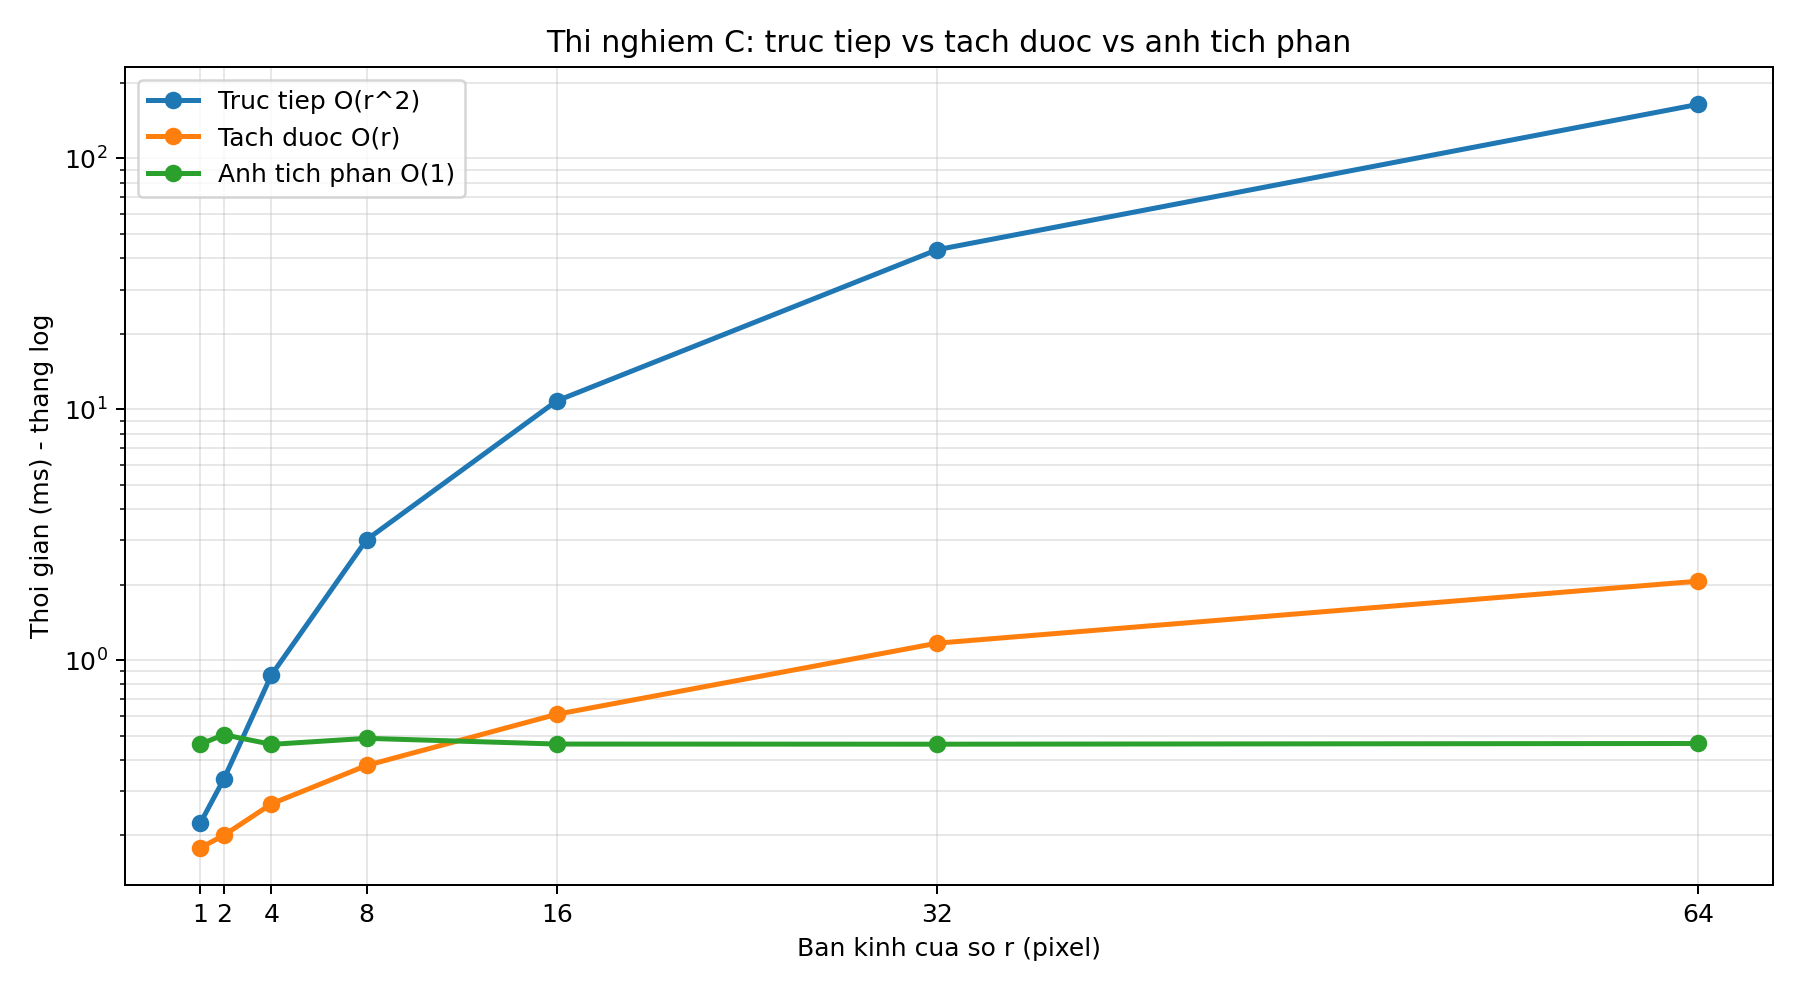

In [12]:
bench_radius, bench_times = experiment_c()
display(Image(filename=str(RESULTS/'C_3_duong_thoi_gian_log.png'),width=1050))

**Nhận xét C:** Đường tích chập trực tiếp tăng nhanh khi r lớn, đường tách được tăng chậm hơn và đường ảnh tích phân gần nằm ngang (độ dao động thời gian do hệ điều hành, bộ nhớ và thao tác cấp phát). Độ phức tạp \(O(1)\) nói tới **truy vấn một cửa sổ**, không phải tổng thời gian xử lý một ảnh; tổng thể với tất cả pixel là \(O(HW)\).

## 10. Kết luận & liên hệ bài học

Ảnh tích phân dùng nguyên lý **bao hàm–loại trừ** để thay vòng lặp tính tổng trên từng cửa sổ bằng bốn lần truy cập. Bradley–Roth là ngưỡng cục bộ theo **trung bình**, Sauvola thêm **độ lệch chuẩn** để điều khiển phản ứng với vùng nền phẳng và vùng có chữ.

**Các lỗi đã tránh:** nhầm `I[y,x]` thành `I[x,y]`; thiếu hàng/cột 0; tràn `uint8` khi bình phương; lấy căn của phương sai âm; chia sai diện tích cửa sổ ở mép.

**Giới hạn:** ảnh test là ảnh tổng hợp; kết quả thực tế phụ thuộc loại nhiễu, kích cỡ ký tự, độ đậm và chiếu sáng. Số đo tốc độ có thể thay đổi tùy máy.